# COCO-MLT follow-up: which relation makes tail classes fire falsely?

The first COCO-MLT check found that tail classes are scored falsely
high on images of **semantically related** classes (+2 to +3 AUC
points), while generic companions such as *person* do almost nothing.
This notebook answers three follow-up questions from the files that
notebook already saved. **No training and no downloads; it takes a
few minutes.**

1. **Similarity or co-occurrence?** Do related classes cause false
   positives even when they *never* appeared together with the tail
   class in the COCO-MLT training images, and does appearing together
   add anything?
2. **Informative scene context.** The first check picked companions by
   raw counts, so most tail classes got *person*. Here, unrelated
   companions are split into *informative* ones (much more common
   with the tail class than overall, such as *car* for a street sign)
   and *generic* ones.
3. **Long tail.** Are tail classes hit harder than head classes?

It also re-checks the first results with exact object counts (Step 9).

## How it works

For a class *t* and another class *c*, take the evaluation images
where *t* is absent. The **false-positive gap** is how much more often
images that contain *c* outrank true positives of *t* than images
without *c*, in AUC points. It is the negatives gap from the first
check, for one class *c* at a time.

Each pair (*t*, *c*) goes into one group, using the 1,909 COCO-MLT
training images (what the model actually saw):

| Group | Meaning |
|---|---|
| related, seen together | *c* is among *t*'s top 5% most text-similar classes and appears in at least one of *t*'s training images |
| related, never together | related, but never in the same training image as *t* |
| unrelated, informative companion | not related; in at least 2 of *t*'s training images and at least twice as common there as overall |
| unrelated, generic companion | not related; in at least 2 of *t*'s training images but not informative (e.g. *person*) |
| unrelated, never together | not related and never with *t* in training: the **baseline** |

Images often contain several classes, so one pair's effect could leak
into another's. To prevent that, each pair (*t*, *c*) only uses
images with no *other* related or informative class of *t*. Pairs
need at least 20 such evaluation images that contain *c* but not
*t*. The two busy-image controls are as before, with one change:
**Control 1** now compares images with exactly the same number of
labelled objects (up to 10). The first check grouped 4 or more
together, and almost 30% of COCO images have 4 or more. **Control 2**
subtracts each image's median score over all classes.

**Rules, set before seeing these results.** A contrast counts as
**SHOWN** only if both controls give a 95% interval above zero and an
estimate of at least 1 AUC point, from at least 10 classes (intervals
resample whole classes). Clear but smaller effects are reported as
negligible. The tail-versus-head comparison uses error ratios, because
AUC gaps shrink for classes that are already near-perfect; tail
classes count as **hit harder** only if both controls give a ratio of
at least x1.25 with an interval above x1.

## Step 0: setup

In [1]:
import contextlib
import importlib
import io
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import sparse

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
print(f"numpy {np.__version__}, pandas {pd.__version__}")
print("context_reliance_check.py: up to date")

numpy 2.5.4, pandas 3.1.0
context_reliance_check.py: up to date


## Step 1: settings

In [2]:
DATA = "coco_mlt"          # folder created by coco_mlt_context_check.ipynb
LOSSES = ["BCE", "ASL", "DB-Focal"]
SEEDS = [42, 43, 44]
RELATED_PCT = 5            # related = top 5% most text-similar (as before)
RELATED_PCT_CHECK = 10     # robustness check with a wider definition
MIN_NEG = 20               # evaluation images with c but not t, per pair
MIN_SHARED = 2             # shared training images for an unrelated companion
INFORMATIVE_LIFT = 2.0     # informative: at least 2x as common with t
COUNT_CAP = 10             # object counts matched exactly up to 10
MIN_CLASSES = crc.MIN_LABELS   # 10 classes needed for a verdict
MIN_EFFECT = 1.0           # AUC points; smaller clear effects = negligible
MIN_RATIO = 1.25           # tail vs head: smallest ratio that counts
RATIO_FLOOR = 0.001        # added to error rates before taking ratios
BOOTSTRAP = 5000
RECHECK_FIRST_RESULTS = True   # Step 9: re-run the first check
OUT = os.path.join(DATA, "results", "followup")
os.makedirs(OUT, exist_ok=True)

GROUPS = ["related, seen together", "related, never together",
          "unrelated, informative companion",
          "unrelated, generic companion", "unrelated, never together"]
BASELINE = GROUPS[4]

pd.DataFrame({
    "setting": ["data folder", "related classes", "pairs need",
                "informative companion", "Control 1",
                "verdict needs", "tail hit harder needs",
                "losses x seeds"],
    "value": [os.path.abspath(DATA),
              f"top {RELATED_PCT}% most text-similar "
              f"(check: top {RELATED_PCT_CHECK}%)",
              f">= {MIN_NEG} evaluation images with c but not t",
              f">= {MIN_SHARED} shared training images, "
              f">= {INFORMATIVE_LIFT:g}x more common with t",
              f"exact object count up to {COUNT_CAP}",
              f">= {MIN_CLASSES} classes, >= {MIN_EFFECT:g} AUC point, "
              f"both controls",
              f"ratio >= x{MIN_RATIO:g}, interval above x1, "
              f"both controls",
              f"{len(LOSSES)} x {len(SEEDS)}"]})

,setting,value
0,data folder,c:\Users\Admin\pilot-20261029T110719Z-1-001\co...
1,related classes,top 5% most text-similar (check: top 10%)
2,pairs need,>= 20 evaluation images with c but not t
3,informative companion,">= 2 shared training images, >= 2x more common..."
4,Control 1,exact object count up to 10
5,verdict needs,">= 10 classes, >= 1 AUC point, both controls"
6,tail hit harder needs,"ratio >= x1.25, interval above x1, both controls"
7,losses x seeds,3 x 3


## Step 2: load the saved inputs and predictions

In [3]:
IN = os.path.join(DATA, "check_inputs")
FILES = {
    "training labels": os.path.join(IN, "training_positives.npz"),
    "evaluation labels": os.path.join(IN, "val_positives.npz"),
    "label table": os.path.join(IN, "labels.csv"),
    "text embeddings": os.path.join(DATA, "features",
                                    "label_text_embeddings.npy"),
    "model selection": os.path.join(DATA, "preds", "selection.csv"),
}
missing = [p for p in FILES.values() if not os.path.exists(p)]
if missing:
    raise SystemExit("Missing (run coco_mlt_context_check.ipynb first): "
                     + ", ".join(missing))

Y_train = sparse.load_npz(FILES["training labels"]).toarray().astype(bool)
Y_val = np.load(FILES["evaluation labels"])["positives"].astype(bool)
label_table = pd.read_csv(FILES["label table"])
names = label_table["display_name"].tolist()
cohort = label_table["cohort"].to_numpy()
L = len(names)
sim = crc.text_similarity(FILES["text embeddings"], None, L)

selection = pd.read_csv(FILES["model selection"])
best = selection.loc[selection.groupby("loss", sort=False)
                     ["held-out mAP"].idxmax()]
CHOSEN = {r["loss"]: (float(r["lr"]), int(r["epochs"]))
          for _, r in best.iterrows()}
PRED = {loss: [os.path.join(DATA, "preds",
                            f"{loss}_lr{CHOSEN[loss][0]:g}_ep"
                            f"{CHOSEN[loss][1]}_seed{seed}.npy")
               for seed in SEEDS] for loss in LOSSES}
absent = [p for paths in PRED.values() for p in paths
          if not os.path.exists(p)]
if absent:
    raise SystemExit("Missing prediction files (run Step 10 of "
                     "coco_mlt_context_check.ipynb): " + ", ".join(absent))

print(f"Training images {Y_train.shape[0]}, evaluation images "
      f"{Y_val.shape[0]}, classes {L}")
pd.DataFrame({
    "loss": LOSSES,
    "chosen settings": [f"lr {CHOSEN[l][0]:g}, {CHOSEN[l][1]} epochs"
                        for l in LOSSES],
    "prediction files": [len(PRED[l]) for l in LOSSES]})

Training images 1909, evaluation images 5000, classes 80


,loss,chosen settings,prediction files
0,BCE,"lr 0.001, 200 epochs",3
1,ASL,"lr 0.001, 50 epochs",3
2,DB-Focal,"lr 0.001, 100 epochs",3


## Step 3: put every class pair into a relation group

Co-occurrence is counted in the COCO-MLT training images. The list
shows each tail class's related classes and how often they appeared
together in training.

In [4]:
shared = Y_train.T.astype(np.int64) @ Y_train.astype(np.int64)
n_train = np.diag(shared).copy()
base_rate = n_train / len(Y_train)


def allowed_negatives(t, flagged):
    """Negatives of t, and for each class c which of them may be used:
    no related or informative class of t other than c itself."""
    P = Y_val[~Y_val[:, t]]
    Fp = P & flagged[t][None, :]
    return P, (Fp.sum(1)[:, None] - Fp) == 0


def relation_groups(pct):
    rows = []
    for t in range(L):
        related = crc.related_labels(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = int(shared[t, c])
            lift = ((k / n_train[t]) / base_rate[c]
                    if n_train[t] and base_rate[c] else np.nan)
            if related[c]:
                group = GROUPS[0] if k >= 1 else GROUPS[1]
            elif k == 0:
                group = GROUPS[4]
            elif k >= MIN_SHARED:
                group = (GROUPS[2] if lift >= INFORMATIVE_LIFT
                         else GROUPS[3])
            else:
                group = "unrelated, together once (not used)"
            rows.append(dict(
                t=t, c=c, target=names[t], cohort=cohort[t],
                other=names[c], group=group, related=bool(related[c]),
                shared_train_images=k,
                target_train_images=int(n_train[t]), lift=lift,
                text_similarity=float(sim[t, c])))
    df = pd.DataFrame(rows)
    flagged = np.zeros((L, L), dtype=bool)
    sel = df["group"].isin(GROUPS[:3])
    flagged[df.loc[sel, "t"], df.loc[sel, "c"]] = True
    n_used = np.zeros((L, L), dtype=int)
    for t in range(L):
        P, allowed = allowed_negatives(t, flagged)
        n_used[t] = (P & allowed).sum(0)
    df["eval_negatives_used"] = n_used[df["t"].to_numpy(),
                                       df["c"].to_numpy()]
    df["used"] = ((df["eval_negatives_used"] >= MIN_NEG)
                  & df["group"].isin(GROUPS))
    return df, flagged


pairs, FLAGGED = relation_groups(RELATED_PCT)
pairs_check, FLAGGED_CHECK = relation_groups(RELATED_PCT_CHECK)

used = pairs[pairs["used"]]
counts = (used.groupby(["cohort", "group"])
          .agg(pairs=("c", "size"), classes=("t", "nunique"))
          .unstack("cohort").reindex(GROUPS).fillna(0).astype(int))
print("Usable pairs, and classes with at least one, per group:")
display(counts)

print("Related classes of each tail class (times seen together in "
      "COCO-MLT training; * = fewer than 20 usable evaluation images, "
      "not used):")
for t in np.flatnonzero(cohort == "tail"):
    rel = pairs[(pairs["t"] == t) & pairs["related"]]
    items = [f"{r.other} ({r.shared_train_images}x"
             f"{'' if r.used else ', *'})" for r in rel.itertuples()]
    print(f"  {names[t]:<14} ({n_train[t]:>2} training images): "
          + ", ".join(items))

Usable pairs, and classes with at least one, per group:


pairs              classes            
cohort                            head medium  tail    head medium tail
group                                                                  
related, seen together              62     64    25      21     30   17
related, never together              9     53    71       7     26   25
unrelated, informative companion   111    131    41      21     31   21
unrelated, generic companion       666    344    69      22     33   25
unrelated, never together          520   1535  1557      21     33   25

Related classes of each tail class (times seen together in COCO-MLT training; * = fewer than 20 usable evaluation images, not used):
  airplane       ( 9 training images): car (3x), train (0x), boat (0x), bird (0x)
  train          (18 training images): car (10x), bus (0x), truck (1x), boat (0x)
  fire hydrant   (11 training images): traffic light (3x), stop sign (1x), parking meter (0x, *), dog (0x)
  stop sign      (13 training images): car (10x), bus (1x), traffic light (0x), pizza (0x)
  parking meter  ( 8 training images): car (7x), traffic light (1x), fire hydrant (0x), cell phone (0x)
  bird           (19 training images): person (14x), cat (1x), dog (1x), horse (0x)
  horse          (17 training images): bird (0x), cat (0x), dog (0x), cow (1x)
  sheep          ( 7 training images): dog (1x), horse (0x), cow (0x), bear (0x)
  cow            (10 training images): dog (0x), horse (1x), sheep (0x), elephant (0x)
  elephant       ( 8 training images): horse (0x), sheep (0x), cow (0x

## Step 4: false-positive gap for every pair

Every evaluation image without class *t* gets a *beat rate*: the
share of *t*'s true positives it outscores. A pair's gap is the mean
beat rate of images with *c* minus that of images without *c*,
matched on exact object count (Control 1) or from image-centred
scores (Control 2), averaged over the 3 seeds. The table shows the
group averages; "no control" is there for comparison only.

In [5]:
objects = np.minimum(Y_val.sum(1), COUNT_CAP)  # labelled objects
LEVELS = np.unique(objects)


def pair_gaps(b, IN, OUT, H):
    """Per class c, from beat rates b of the negatives: gap with no
    control, gap matched on object count, and the error rates (mean
    beat rates) behind each. IN/OUT: negatives with/without c that may
    be used; H: one-hot object count of each negative."""
    a, o = H.T @ IN, H.T @ OUT                  # counts per level
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN, Hb.T @ OUT              # beat-rate sums
    with np.errstate(invalid="ignore", divide="ignore"):
        e_in = sa.sum(0) / a.sum(0)
        e_out = so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        ma = np.where(ok, sa / np.maximum(a, 1), 0.0)
        mo = np.where(ok, so / np.maximum(o, 1), 0.0)
        den = w.sum(0)
        return (e_in - e_out, (w * (ma - mo)).sum(0) / den, e_in, e_out,
                (w * ma).sum(0) / den, (w * mo).sum(0) / den)


def log_ratio(e_in, e_out):
    return np.log((e_in + RATIO_FLOOR) / (e_out + RATIO_FLOOR))


MEASURES = ["gap_none", "gap_c1", "gap_c2", "logratio_c1", "logratio_c2"]


t0 = time.time()
SCORES = {}   # loss -> list of (scores, image-centred scores), one per seed
for loss in LOSSES:
    for path in PRED[loss]:
        S = np.load(path).astype(np.float64)
        if S.shape != Y_val.shape:
            raise SystemExit(f"{path} has shape {S.shape}; expected "
                             f"{Y_val.shape}.")
        SCORES.setdefault(loss, []).append(
            (S, S - np.median(S, axis=1, keepdims=True)))


def compute_gaps(flagged):
    sums = {(loss, m): np.zeros((L, L)) for loss in LOSSES
            for m in MEASURES}
    for t in range(L):
        pos = Y_val[:, t]
        if not pos.any() or pos.all():
            continue
        P, allowed = allowed_negatives(t, flagged)
        IN = (P & allowed).astype(float)
        OUT = (~P & allowed).astype(float)
        H = (objects[~pos][:, None] == LEVELS[None, :]).astype(float)
        for loss in LOSSES:
            for S, S_c in SCORES[loss]:
                b = crc.beat_rates(S[~pos, t], S[pos, t])
                bc = crc.beat_rates(S_c[~pos, t], S_c[pos, t])
                none, c1, _, _, m_in, m_out = pair_gaps(b, IN, OUT, H)
                c2, _, ec_in, ec_out, _, _ = pair_gaps(bc, IN, OUT, H)
                for m, v in (("gap_none", none), ("gap_c1", c1),
                             ("gap_c2", c2),
                             ("logratio_c1", log_ratio(m_in, m_out)),
                             ("logratio_c2", log_ratio(ec_in, ec_out))):
                    sums[(loss, m)][t] += v
    frames = []
    ti, ci = pairs["t"].to_numpy(), pairs["c"].to_numpy()
    for loss in LOSSES:
        frame = pairs[["t", "c"]].copy()
        frame["loss"] = loss
        for m in MEASURES:
            frame[m] = (sums[(loss, m)] / len(SCORES[loss]))[ti, ci]
        frames.append(frame)
    out = pd.concat(frames)
    for m in ("gap_none", "gap_c1", "gap_c2"):
        out[m] *= 100   # AUC points
    return out


gaps = pairs.merge(compute_gaps(FLAGGED), on=["t", "c"])
gaps_check = pairs_check.merge(compute_gaps(FLAGGED_CHECK), on=["t", "c"])
print(f"Computed {len(gaps):,} pair results ({len(LOSSES)} losses, "
      f"{len(SEEDS)} seeds each, plus the top-{RELATED_PCT_CHECK}% "
      f"check) in {time.time() - t0:.0f} s. Group averages, AUC points:")
(gaps[gaps["used"]].groupby(["loss", "group"], sort=False)
 [["gap_none", "gap_c1", "gap_c2"]].mean().round(2)
 .rename(columns={"gap_none": "no control", "gap_c1": "Control 1",
                  "gap_c2": "Control 2"})
 .unstack("loss").reindex(GROUPS))

Computed 18,960 pair results (3 losses, 3 seeds each, plus the top-10% check) in 10 s. Group averages, AUC points:


no control                Control 1        \
loss                                    BCE   ASL DB-Focal       BCE   ASL   
group                                                                        
related, seen together                 5.91  5.71     5.72      5.63  5.42   
related, never together                1.49  1.49     1.11      1.50  1.51   
unrelated, informative companion       5.60  5.50     5.58      5.49  5.38   
unrelated, generic companion           1.26  1.22     1.51      0.97  0.94   
unrelated, never together             -0.34 -0.31    -0.47     -0.31 -0.30   

                                          Control 2                 
loss                             DB-Focal       BCE   ASL DB-Focal  
group                                                               
related, seen together               5.45      5.71  5.47     5.00  
related, never together              1.15      1.46  1.45     1.17  
unrelated, informative companion     5.51      5.40  5.25     5.05  
unrelated, generic companion         1.23      0.93  0.82     0.62  
unrelated, never together           -0.44     -0.45 -0.44    -0.44

## Step 5: main result for tail classes

Each row compares two groups *within* the same tail classes (classes
that have pairs in both), in AUC points. The verdict follows the
rules at the top. The last table repeats the verdicts with a wider
definition of related (top 10%) as a robustness check.

In [6]:
CONTRASTS = [
    ("similarity alone", GROUPS[1], BASELINE,
     "related (never together) vs baseline"),
    ("co-occurrence on top of similarity", GROUPS[0], GROUPS[1],
     "related: seen together vs never together"),
    ("related and seen together", GROUPS[0], BASELINE,
     "related (seen together) vs baseline"),
    ("informative scene context", GROUPS[2], BASELINE,
     "informative companion vs baseline"),
    ("generic context", GROUPS[3], BASELINE,
     "generic companion vs baseline"),
]


def contrast(df, a, b, value, rng):
    m = (df[df["used"]].groupby(["t", "group"])[value].mean()
         .unstack("group"))
    if a not in m or b not in m:
        return dict(crc.EMPTY)
    return crc.summarize((m[a] - m[b]).dropna().to_numpy(),
                         BOOTSTRAP, rng)


def verdict(r1, r2):
    if min(r1["n_labels"], r2["n_labels"]) < MIN_CLASSES:
        return "NOT ENOUGH DATA"
    if r1["ci_low"] > 0 and r2["ci_low"] > 0:
        if min(r1["mean"], r2["mean"]) >= MIN_EFFECT:
            return "SHOWN"
        return "NEGLIGIBLE (clear, under 1 point)"
    if r1["ci_high"] < 0 and r2["ci_high"] < 0:
        if max(r1["mean"], r2["mean"]) <= -MIN_EFFECT:
            return "REVERSED"
        return "NEGLIGIBLE (clear, under 1 point)"
    return "NOT SHOWN"


def est(r):
    if not r["n_labels"] or not np.isfinite(r["mean"]):
        return "not enough data"
    return (f"{r['mean']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}] "
            f"(n={r['n_labels']})")


def all_contrasts(table, cohorts, rng):
    rows = []
    for coh in cohorts:
        for loss in LOSSES:
            df = table[(table["cohort"] == coh) & (table["loss"] == loss)]
            for question, a, b, label in CONTRASTS:
                r1 = contrast(df, a, b, "gap_c1", rng)
                r2 = contrast(df, a, b, "gap_c2", rng)
                rows.append(dict(
                    cohort=coh, loss=loss, question=question,
                    comparison=label, control_1=est(r1),
                    control_2=est(r2), verdict=verdict(r1, r2),
                    c1_mean=r1["mean"], c1_low=r1["ci_low"],
                    c1_high=r1["ci_high"], c2_mean=r2["mean"],
                    c2_low=r2["ci_low"], c2_high=r2["ci_high"],
                    classes=min(r1["n_labels"], r2["n_labels"])))
    return pd.DataFrame(rows)


contrasts = all_contrasts(gaps, ("tail", "medium", "head"),
                          np.random.default_rng(0))
contrasts_check = all_contrasts(gaps_check, ("tail",),
                                np.random.default_rng(0))
for loss in LOSSES:
    print(f"Tail classes, {loss} (AUC points, 95% interval, classes)")
    display(contrasts[(contrasts["cohort"] == "tail")
                      & (contrasts["loss"] == loss)]
            .set_index("question")[["comparison", "control_1",
                                    "control_2", "verdict"]])
print(f"Robustness: verdicts with related = top {RELATED_PCT_CHECK}%")
(contrasts_check.pivot(index="question", columns="loss",
                       values="verdict")
 .reindex(index=[q for q, *_ in CONTRASTS], columns=LOSSES))

Tail classes, BCE (AUC points, 95% interval, classes)


,comparison,control_1,control_2,verdict
question,,,,
similarity alone,related (never together) vs baseline,"+1.65 [+0.70, +2.76] (n=25)","+1.76 [+0.81, +2.81] (n=25)",SHOWN
co-occurrence on top of similarity,related: seen together vs never together,"+5.37 [+0.80, +10.63] (n=17)","+4.86 [+0.33, +10.08] (n=17)",SHOWN
related and seen together,related (seen together) vs baseline,"+7.56 [+3.52, +12.38] (n=17)","+7.21 [+3.15, +12.13] (n=17)",SHOWN
informative scene context,informative companion vs baseline,"+1.36 [+0.65, +2.18] (n=21)","+0.99 [+0.30, +1.83] (n=21)","NEGLIGIBLE (clear, under 1 point)"
generic context,generic companion vs baseline,"+0.35 [+0.10, +0.62] (n=25)","-0.04 [-0.25, +0.18] (n=25)",NOT SHOWN


Tail classes, ASL (AUC points, 95% interval, classes)


,comparison,control_1,control_2,verdict
question,,,,
similarity alone,related (never together) vs baseline,"+1.63 [+0.70, +2.72] (n=25)","+1.71 [+0.74, +2.85] (n=25)",SHOWN
co-occurrence on top of similarity,related: seen together vs never together,"+5.07 [+0.64, +10.38] (n=17)","+4.60 [-0.02, +10.00] (n=17)",NOT SHOWN
related and seen together,related (seen together) vs baseline,"+7.25 [+3.34, +11.97] (n=17)","+6.91 [+2.91, +11.82] (n=17)",SHOWN
informative scene context,informative companion vs baseline,"+1.38 [+0.56, +2.28] (n=21)","+0.89 [+0.23, +1.72] (n=21)","NEGLIGIBLE (clear, under 1 point)"
generic context,generic companion vs baseline,"+0.24 [-0.09, +0.56] (n=25)","-0.06 [-0.30, +0.17] (n=25)",NOT SHOWN


Tail classes, DB-Focal (AUC points, 95% interval, classes)


,comparison,control_1,control_2,verdict
question,,,,
similarity alone,related (never together) vs baseline,"+1.57 [+0.71, +2.59] (n=25)","+1.62 [+0.82, +2.54] (n=25)",SHOWN
co-occurrence on top of similarity,related: seen together vs never together,"+5.50 [+0.99, +10.81] (n=17)","+4.68 [+0.31, +10.08] (n=17)",SHOWN
related and seen together,related (seen together) vs baseline,"+7.65 [+3.58, +12.42] (n=17)","+6.86 [+2.93, +11.72] (n=17)",SHOWN
informative scene context,informative companion vs baseline,"+1.57 [+0.60, +2.65] (n=21)","+0.90 [+0.19, +1.75] (n=21)","NEGLIGIBLE (clear, under 1 point)"
generic context,generic companion vs baseline,"+0.19 [-0.31, +0.63] (n=25)","-0.04 [-0.27, +0.18] (n=25)",NOT SHOWN


Robustness: verdicts with related = top 10%


loss,BCE,ASL,DB-Focal
question,,,
similarity alone,SHOWN,SHOWN,SHOWN
co-occurrence on top of similarity,SHOWN,NOT SHOWN,NOT SHOWN
related and seen together,SHOWN,SHOWN,SHOWN
informative scene context,"NEGLIGIBLE (clear, under 1 point)","NEGLIGIBLE (clear, under 1 point)","NEGLIGIBLE (clear, under 1 point)"
generic context,NOT SHOWN,NOT SHOWN,NOT SHOWN


## Step 6: figure

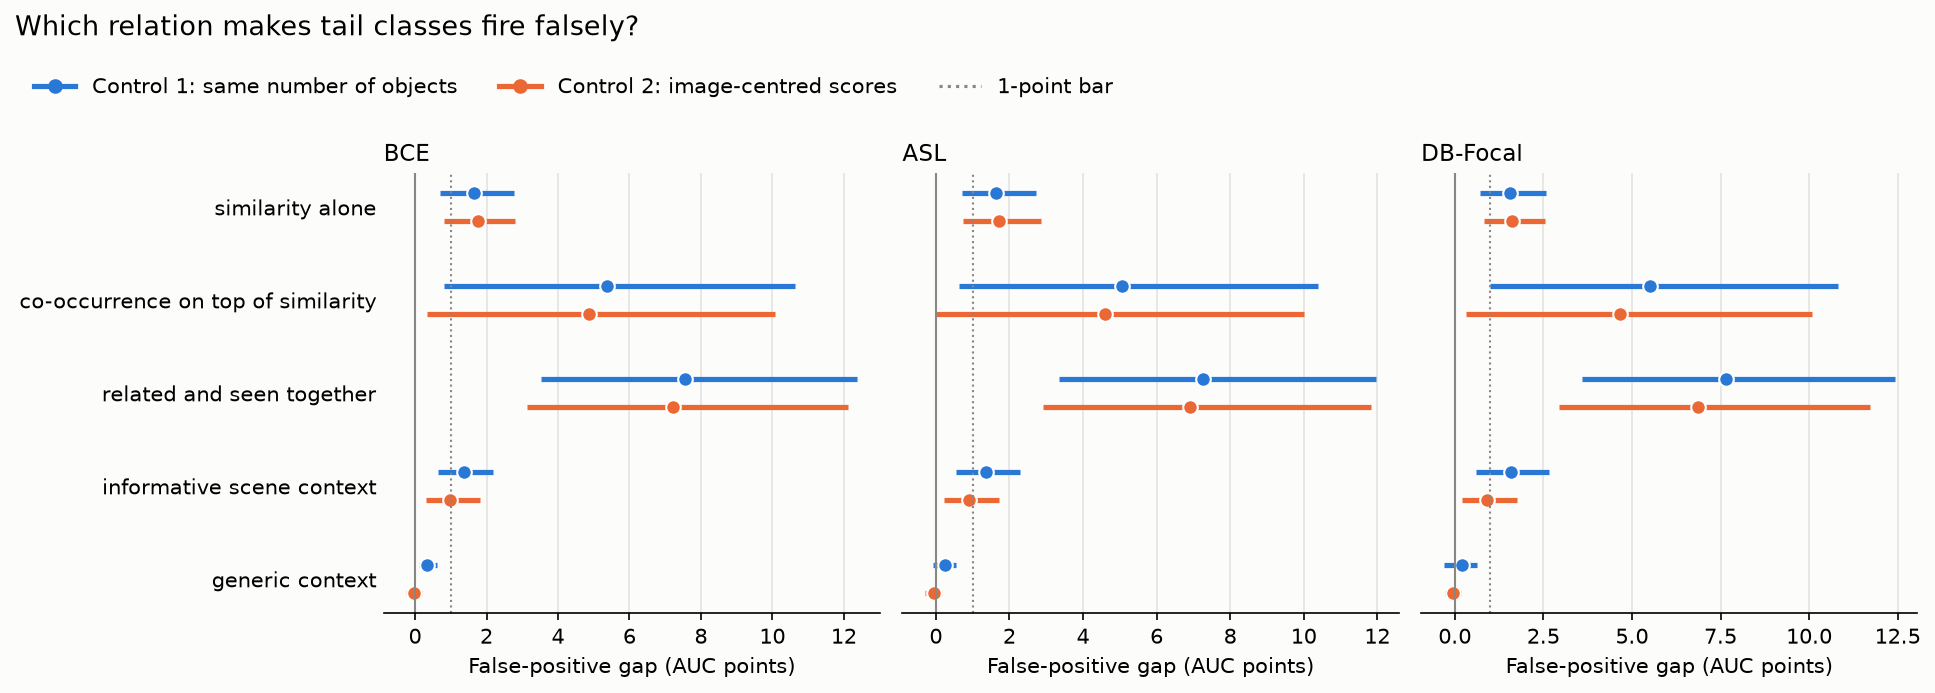

Saved coco_mlt\results\followup\relation_test.png


In [7]:
BLUE, ORANGE, MUTED, SURFACE = "#2a78d6", "#eb6834", "#898781", "#fcfcfb"
tail = contrasts[contrasts["cohort"] == "tail"]
questions = [q for q, *_ in CONTRASTS]
fig, axes = plt.subplots(1, len(LOSSES), figsize=(13, 4.2), sharey=True,
                         facecolor=SURFACE)
for ax, loss in zip(axes, LOSSES):
    ax.set_facecolor(SURFACE)
    sub = tail[tail["loss"] == loss].set_index("question").reindex(questions)
    y = np.arange(len(questions))[::-1]
    for off, col, key in ((0.15, BLUE, "c1"), (-0.15, ORANGE, "c2")):
        m = sub[f"{key}_mean"].to_numpy(float)
        lo = sub[f"{key}_low"].to_numpy(float)
        hi = sub[f"{key}_high"].to_numpy(float)
        ok = np.isfinite(m)
        ax.hlines(y[ok] + off, lo[ok], hi[ok], color=col, lw=2.5)
        ax.plot(m[ok], y[ok] + off, "o", color=col, ms=7, mec="white")
    ax.axvline(0, color=MUTED, lw=1)
    ax.axvline(MIN_EFFECT, color=MUTED, lw=1, ls=":")
    ax.set_title(loss, loc="left", fontsize=11)
    ax.set_yticks(y)
    ax.set_yticklabels(questions)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("False-positive gap (AUC points)")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="x", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
handles = [plt.Line2D([], [], color=BLUE, marker="o", lw=2.5,
                      label="Control 1: same number of objects"),
           plt.Line2D([], [], color=ORANGE, marker="o", lw=2.5,
                      label="Control 2: image-centred scores"),
           plt.Line2D([], [], color=MUTED, ls=":",
                      label="1-point bar")]
fig.legend(handles=handles, loc="upper left", ncol=3, frameon=False,
           bbox_to_anchor=(0.01, 1.02))
fig.suptitle("Which relation makes tail classes fire falsely?",
             x=0.01, y=1.09, ha="left", fontsize=13)
fig.tight_layout()
FIG = os.path.join(OUT, "relation_test.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 7: are tail classes hit harder than head classes?

For each class: how many times more often images of its related
classes outrank its true positives than images of unrelated classes.
This error ratio stays comparable when a class is already
near-perfect. Above x1 means related classes cause more false
positives. The last lines compare tail with head classes.

In [8]:
def related_vs_unrelated(df, value):
    d = df[df["eval_negatives_used"] >= MIN_NEG]
    m = d.groupby(["t", "related"])[value].mean().unstack("related")
    if True not in m or False not in m:
        return np.array([])
    return (m[True] - m[False]).dropna().to_numpy()


rng = np.random.default_rng(1)
rows, diffs = [], []
for loss in LOSSES:
    per = {}
    for coh in ("tail", "medium", "head"):
        df = gaps[(gaps["cohort"] == coh) & (gaps["loss"] == loss)]
        row = dict(loss=loss, cohort=coh)
        for key in ("c1", "c2"):
            x = related_vs_unrelated(df, f"logratio_{key}")
            per[(coh, key)] = x
            if x.size:
                boots = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
                lo, hi = np.percentile(boots, [2.5, 97.5])
                row[f"Control {key[1]}"] = (
                    f"x{np.exp(x.mean()):.2f} [x{np.exp(lo):.2f}, "
                    f"x{np.exp(hi):.2f}] (n={x.size})")
            g = related_vs_unrelated(df, f"gap_{key}")
            if g.size:
                row[f"Control {key[1]}, AUC points"] = f"{g.mean():+.2f}"
        rows.append(row)
    for key in ("c1", "c2"):
        a, b = per[("tail", key)], per[("head", key)]
        if a.size >= MIN_CLASSES and b.size >= MIN_CLASSES:
            boots = (rng.choice(a, size=(BOOTSTRAP, a.size)).mean(1)
                     - rng.choice(b, size=(BOOTSTRAP, b.size)).mean(1))
            lo, hi = np.percentile(boots, [2.5, 97.5])
            diffs.append(dict(loss=loss, control=key[1],
                              tail_over_head=np.exp(a.mean() - b.mean()),
                              low=np.exp(lo), high=np.exp(hi)))
cohorts = pd.DataFrame(rows)
print("Related vs unrelated classes: error ratio (x more false "
      "positives), 95% interval, classes")
display(cohorts.set_index(["loss", "cohort"]))
diff = pd.DataFrame(diffs)
if len(diff):
    for loss in LOSSES:
        d = diff[diff["loss"] == loss]
        hit = (len(d) == 2 and (d["low"] > 1).all()
               and (d["tail_over_head"] >= MIN_RATIO).all())
        print(f"{loss}: tail / head = "
              + "; ".join(f"Control {r.control} x{r.tail_over_head:.2f} "
                          f"[x{r.low:.2f}, x{r.high:.2f}]"
                          for r in d.itertuples())
              + f"  ->  {'TAIL HIT HARDER' if hit else 'NOT SHOWN'}")
else:
    print("Not enough head or tail classes for the comparison.")

Related vs unrelated classes: error ratio (x more false positives), 95% interval, classes


Control 1 Control 1, AUC points  \
loss     cohort                                                      
BCE      tail    x1.76 [x1.50, x2.10] (n=25)                 +2.65   
         medium  x1.39 [x1.27, x1.53] (n=33)                 +2.89   
         head    x1.47 [x1.27, x1.71] (n=22)                 +5.09   
ASL      tail    x1.65 [x1.43, x1.94] (n=25)                 +2.56   
         medium  x1.36 [x1.25, x1.49] (n=33)                 +2.79   
         head    x1.49 [x1.30, x1.73] (n=22)                 +4.98   
DB-Focal tail    x1.50 [x1.34, x1.71] (n=25)                 +2.55   
         medium  x1.29 [x1.17, x1.41] (n=33)                 +2.51   
         head    x1.45 [x1.27, x1.65] (n=22)                 +4.93   

                                   Control 2 Control 2, AUC points  
loss     cohort                                                     
BCE      tail    x1.88 [x1.54, x2.32] (n=25)                 +2.67  
         medium  x1.39 [x1.27, x1.53] (n=33)                 +2.98  
         head    x1.51 [x1.31, x1.77] (n=22)                 +5.46  
ASL      tail    x1.77 [x1.48, x2.15] (n=25)                 +2.57  
         medium  x1.35 [x1.25, x1.48] (n=33)                 +2.88  
         head    x1.53 [x1.31, x1.79] (n=22)                 +5.32  
DB-Focal tail    x1.71 [x1.46, x2.03] (n=25)                 +2.48  
         medium  x1.27 [x1.17, x1.39] (n=33)                 +2.48  
         head    x1.41 [x1.24, x1.64] (n=22)                 +4.77

BCE: tail / head = Control 1 x1.20 [x0.96, x1.50]; Control 2 x1.24 [x0.97, x1.61]  ->  NOT SHOWN
ASL: tail / head = Control 1 x1.11 [x0.90, x1.36]; Control 2 x1.16 [x0.91, x1.49]  ->  NOT SHOWN
DB-Focal: tail / head = Control 1 x1.04 [x0.87, x1.25]; Control 2 x1.21 [x0.98, x1.50]  ->  NOT SHOWN


## Step 8: examples to quote

The tail pairs with the largest false-positive gaps (BCE, image-centred
scores), with how often the two classes appeared together in training.
Single pairs are noisy: quote them only to illustrate an effect that
Step 5 shows.

In [9]:
show = ["target", "other", "group", "shared_train_images",
        "target_train_images", "eval_negatives_used", "gap_c1",
        "gap_c2"]
ex = gaps[(gaps["cohort"] == "tail") & (gaps["loss"] == "BCE")
          & gaps["used"]]
print("Largest gaps among related pairs:")
display(ex[ex["related"]].sort_values("gap_c2", ascending=False)[show]
        .head(12).round(2).reset_index(drop=True))
print("Largest gaps among informative companions:")
display(ex[ex["group"] == GROUPS[2]].sort_values("gap_c2",
                                                  ascending=False)[show]
        .head(8).round(2).reset_index(drop=True))

Largest gaps among related pairs:


,target,other,group,shared_train_images,target_train_images,eval_negatives_used,gap_c1,gap_c2
0,snowboard,skis,"related, seen together",3,8,106,32.98,33.89
1,skis,snowboard,"related, seen together",3,12,33,26.66,26.57
2,parking meter,fire hydrant,"related, never together",0,8,36,19.54,19.20
3,kite,airplane,"related, never together",0,10,78,12.76,13.91
4,hot dog,sandwich,"related, seen together",1,14,59,13.51,12.79
5,scissors,toothbrush,"related, never together",0,15,22,13.92,12.55
6,fire hydrant,stop sign,"related, seen together",1,11,31,11.03,11.96
7,toaster,oven,"related, seen together",7,9,25,15.13,11.62
8,cow,sheep,"related, never together",0,10,47,9.75,10.59
9,fire hydrant,traffic light,"related, seen together",3,11,44,9.88,9.25


Largest gaps among informative companions:


,target,other,group,shared_train_images,target_train_images,eval_negatives_used,gap_c1,gap_c2
0,bird,boat,"unrelated, informative companion",2,19,27,10.04,9.80
1,toothbrush,sink,"unrelated, informative companion",9,11,96,9.21,8.33
2,stop sign,truck,"unrelated, informative companion",5,13,77,6.23,6.35
3,toaster,bowl,"unrelated, informative companion",5,9,76,5.84,4.22
4,toaster,refrigerator,"unrelated, informative companion",3,9,32,7.54,3.93
5,fire hydrant,car,"unrelated, informative companion",8,11,284,2.45,2.53
6,bird,bench,"unrelated, informative companion",3,19,42,3.35,2.41
7,bird,clock,"unrelated, informative companion",2,19,111,2.68,2.28


## Step 9: re-check the first results with exact object counts

Re-runs the first check (tail classes; all, context-only and
related-only companions) with Control 1 matching exact object counts
up to 10, and puts Control 1 next to the original. Control 2 does not
depend on object counts, so it is unchanged. *verdict* uses the first
check's rule; *with_1_point_rule* adds the 1-point bar. Takes a
minute or two; set `RECHECK_FIRST_RESULTS = False` in Step 1 to skip.

In [10]:
def short(r):
    if r is None:
        return "-"
    if r["n_labels"] == 0 or not np.isfinite(r["mean"]):
        return "not enough data"
    return f"{r['mean']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"


def pick(summary, loss, measure):
    if summary is None:
        return None
    hit = summary[(summary["condition"] == loss)
                  & (summary["measure"] == measure)]
    return hit.iloc[0] if len(hit) else None


if RECHECK_FIRST_RESULTS:
    base_argv = [
        "--train-pos", FILES["training labels"],
        "--val-pos", FILES["evaluation labels"],
        "--val-neg", os.path.join(IN, "val_negatives.npz"),
        "--labels", FILES["label table"],
        "--cooc", os.path.join(IN, "cooc_train2017.npz"),
        "--label-embeddings", FILES["text embeddings"],
        "--related-pct", str(RELATED_PCT), "--no-plots"]
    for loss in LOSSES:
        base_argv += ["--pred", f"{loss}=" + ",".join(PRED[loss])]
    old_cap, crc.OBJECT_CAP = crc.OBJECT_CAP, COUNT_CAP
    rows = []
    t0 = time.time()
    try:
        for mode in ("all", "context", "related"):
            out_dir = os.path.join(OUT, "first_check_exact_counts", mode)
            log = io.StringIO()
            with contextlib.redirect_stdout(log):
                try:
                    crc.main(base_argv + ["--companions", mode,
                                          "--out", out_dir])
                except SystemExit as stop:
                    if stop.code not in (0, None):
                        print("Stopped:", stop.code)
            new = pd.read_csv(os.path.join(out_dir, "summary.csv"))
            old_path = os.path.join(DATA, "results", mode, "summary.csv")
            old = pd.read_csv(old_path) if os.path.exists(old_path) else None
            for loss in LOSSES:
                for side, word in (("neg", "negatives"),
                                   ("pos", "positives")):
                    c1 = pick(new, loss, f"matched_{side}")
                    c2 = pick(new, loss, f"centred_{side}")
                    ok = c1 is not None and c2 is not None
                    rows.append(dict(
                        companions=mode, loss=loss, side=word,
                        control_1_before=short(pick(old, loss,
                                                    f"matched_{side}")),
                        control_1_exact=short(c1), control_2=short(c2),
                        verdict=(crc.verdict(c1, c2, "").split(" - ")[0]
                                 if ok else "-"),
                        with_1_point_rule=(verdict(c1, c2) if ok
                                           else "-")))
    finally:
        crc.OBJECT_CAP = old_cap
    recheck = pd.DataFrame(rows)
    print(f"Re-ran the first check in {time.time() - t0:.0f} s "
          f"(AUC points, 95% interval):")
    display(recheck.set_index(["companions", "side", "loss"]))
else:
    recheck = None
    print("Skipped (RECHECK_FIRST_RESULTS = False).")

Re-ran the first check in 16 s (AUC points, 95% interval):


control_1_before        control_1_exact  \
companions side      loss                                                     
all        negatives BCE        +0.77 [+0.50, +1.06]   +0.76 [+0.49, +1.05]   
           positives BCE       +5.98 [+2.59, +10.77]  +5.29 [+0.90, +10.26]   
           negatives ASL        +0.56 [+0.28, +0.90]   +0.55 [+0.28, +0.86]   
           positives ASL       +5.92 [+2.55, +11.05]  +5.21 [+1.06, +10.47]   
           negatives DB-Focal   +0.12 [-0.25, +0.50]   +0.12 [-0.25, +0.49]   
           positives DB-Focal  +6.19 [+2.14, +11.25]  +5.65 [+0.64, +11.00]   
context    negatives BCE        +0.66 [+0.37, +0.98]   +0.65 [+0.36, +0.96]   
           positives BCE        +2.21 [+0.09, +4.91]   +1.06 [-1.49, +3.85]   
           negatives ASL        +0.49 [+0.11, +0.89]   +0.48 [+0.10, +0.85]   
           positives ASL        +2.53 [+0.47, +5.20]   +1.34 [-1.12, +3.98]   
           negatives DB-Focal   +0.08 [-0.41, +0.53]   +0.08 [-0.41, +0.52]   
           positives DB-Focal   +3.93 [+1.79, +6.61]   +2.82 [-0.04, +5.46]   
related    negatives BCE        +2.83 [+1.58, +4.31]   +2.85 [+1.62, +4.32]   
           positives BCE        +1.62 [-0.69, +4.52]   +2.58 [+0.19, +5.77]   
           negatives ASL        +2.66 [+1.54, +4.06]   +2.67 [+1.56, +4.02]   
           positives ASL        +1.34 [-1.13, +4.41]   +2.36 [-0.16, +5.68]   
           negatives DB-Focal   +2.34 [+1.30, +3.61]   +2.37 [+1.34, +3.64]   
           positives DB-Focal   +1.34 [-1.61, +4.74]   +2.28 [-0.89, +6.02]   

                                          control_2    verdict  \
companions side      loss                                        
all        negatives BCE       +0.25 [+0.03, +0.48]      CLEAR   
           positives BCE       -2.82 [-5.13, -0.98]      MIXED   
           negatives ASL       +0.19 [-0.04, +0.43]      MIXED   
           positives ASL       -2.96 [-5.14, -1.11]      MIXED   
           negatives DB-Focal  +0.21 [-0.04, +0.47]  NOT CLEAR   
           positives DB-Focal  -3.10 [-5.50, -1.21]      MIXED   
context    negatives BCE       +0.18 [-0.10, +0.46]      MIXED   
           positives BCE       -3.35 [-6.02, -1.14]      MIXED   
           negatives ASL       +0.14 [-0.17, +0.42]      MIXED   
           positives ASL       -3.46 [-6.06, -1.20]      MIXED   
           negatives DB-Focal  +0.17 [-0.14, +0.47]  NOT CLEAR   
           positives DB-Focal  -3.46 [-6.30, -1.31]      MIXED   
related    negatives BCE       +2.32 [+1.10, +3.83]      CLEAR   
           positives BCE       -3.84 [-6.70, -1.15]      MIXED   
           negatives ASL       +2.15 [+1.02, +3.52]      CLEAR   
           positives ASL       -4.10 [-6.76, -1.45]      MIXED   
           negatives DB-Focal  +1.98 [+1.03, +3.21]      CLEAR   
           positives DB-Focal  -3.86 [-6.63, -1.31]      MIXED   

                                               with_1_point_rule  
companions side      loss                                         
all        negatives BCE       NEGLIGIBLE (clear, under 1 point)  
           positives BCE                               NOT SHOWN  
           negatives ASL                               NOT SHOWN  
           positives ASL                               NOT SHOWN  
           negatives DB-Focal                          NOT SHOWN  
           positives DB-Focal                          NOT SHOWN  
context    negatives BCE                               NOT SHOWN  
           positives BCE                               NOT SHOWN  
           negatives ASL                               NOT SHOWN  
           positives ASL                               NOT SHOWN  
           negatives DB-Focal                          NOT SHOWN  
           positives DB-Focal                          NOT SHOWN  
related    negatives BCE                                   SHOWN  
           positives BCE                               NOT SHOWN  
           negatives ASL                                   SHO

## Step 10: save the results

In [11]:
gaps.to_csv(os.path.join(OUT, "pairs.csv"), index=False)
contrasts.to_csv(os.path.join(OUT, "contrasts.csv"), index=False)
contrasts_check.to_csv(os.path.join(OUT, "contrasts_top10pct.csv"),
                       index=False)
cohorts.to_csv(os.path.join(OUT, "cohorts.csv"), index=False)
if len(diff):
    diff.to_csv(os.path.join(OUT, "tail_vs_head.csv"), index=False)
if recheck is not None:
    recheck.to_csv(os.path.join(OUT, "first_check_exact_counts.csv"),
                   index=False)
lines = []
for loss in LOSSES:
    lines.append(f"Tail classes, {loss}:")
    sub = contrasts[(contrasts["cohort"] == "tail")
                    & (contrasts["loss"] == loss)]
    for r in sub.itertuples():
        lines.append(f"  {r.question:<36} {r.verdict:<34} "
                     f"C1 {r.control_1} | C2 {r.control_2}")
with open(os.path.join(OUT, "summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
print(f"\nSaved the tables and summary.txt to {os.path.abspath(OUT)}")

Tail classes, BCE:
  similarity alone                     SHOWN                              C1 +1.65 [+0.70, +2.76] (n=25) | C2 +1.76 [+0.81, +2.81] (n=25)
  co-occurrence on top of similarity   SHOWN                              C1 +5.37 [+0.80, +10.63] (n=17) | C2 +4.86 [+0.33, +10.08] (n=17)
  related and seen together            SHOWN                              C1 +7.56 [+3.52, +12.38] (n=17) | C2 +7.21 [+3.15, +12.13] (n=17)
  informative scene context            NEGLIGIBLE (clear, under 1 point)  C1 +1.36 [+0.65, +2.18] (n=21) | C2 +0.99 [+0.30, +1.83] (n=21)
  generic context                      NOT SHOWN                          C1 +0.35 [+0.10, +0.62] (n=25) | C2 -0.04 [-0.25, +0.18] (n=25)
Tail classes, ASL:
  similarity alone                     SHOWN                              C1 +1.63 [+0.70, +2.72] (n=25) | C2 +1.71 [+0.74, +2.85] (n=25)
  co-occurrence on top of similarity   NOT SHOWN                          C1 +5.07 [+0.64, +10.38] (n=17) | C2 +4.60 [-0.02, +10.0

## How to read the results

Start with the **Step 5** verdicts (ideally the three losses agree):

| If this is SHOWN | It means | For the method |
|---|---|---|
| similarity alone | related classes cause false positives even without ever co-occurring | choose hard negatives by semantic relation (text similarity) |
| co-occurrence on top of similarity | related classes that also co-occur are worse | weight related negatives by co-occurrence too |
| informative scene context | informative unrelated companions also cause false positives | add informative companions as negatives |
| generic context | generic companions matter (not expected; the first check found under 1 point) | revisit the context idea |

If *similarity alone* is SHOWN but *co-occurrence on top of
similarity* is not, the relation that matters is semantic similarity,
and co-occurrence statistics are not needed to choose negatives.
**Step 7** says whether the problem is specific to the long tail, and
**Step 9** whether the first results hold with exact object counts.
